# Segmentation des clients — Instacart

Cette analyse est distincte du dataset FoodData Central : elle utilise l’historique de commandes Instacart pour créer des profils clients. Les identifiants `user_id` sont ceux pseudonymisés du jeu public.

Méthode retenue : **MiniBatchKMeans**, adaptée à plus de 200 000 clients. Les commandes `prior` seulement servent à construire les variables; les commandes d’évaluation `train` et `test` ne sont pas utilisées, afin de ne pas regarder les commandes futures. Le choix de k est comparé de 2 à 10 avec inertie (coude) et silhouette sur un échantillon.

In [ ]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in candidates if (path / "segmenter_clients_instacart.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Impossible de localiser segmenter_clients_instacart.py")

INSTACART_DIR = ROOT.parent / "archive (1)"
OUT_DIR = ROOT / "data" / "processed" / "instacart_segmentation"
REPORT_PATH = OUT_DIR / "instacart_segmentation_report.json"
RECALCULER = False

if RECALCULER or not REPORT_PATH.exists():
    subprocess.run([
        sys.executable,
        str(ROOT / "segmenter_clients_instacart.py"),
        "--input-dir", str(INSTACART_DIR),
        "--output-dir", str(OUT_DIR),
    ], cwd=ROOT, check=True)

with REPORT_PATH.open(encoding="utf-8") as report_file:
    rapport = json.load(report_file)
print("Données Instacart :", INSTACART_DIR)

## 1. Données et variables construites

Les profils regroupent le nombre de commandes antérieures, les jours entre commandes, la taille et la composition des paniers, le taux de réachat, les horaires/jours de commande et la part des produits par département. Les comptes très asymétriques sont transformés par `log1p`; les variables sont imputées par la médiane puis mises à l’échelle avec `RobustScaler`.

Les articles sont associés aux clients par `order_id` et aux rayons par `product_id`. Les tables `products.csv` et `departments.csv` donnent les départements nécessaires à l’interprétation des paniers.

In [2]:
resume = {
    "commandes totales": rapport["orders_total"],
    "clients pseudonymisés": rapport["users_total"],
    "commandes historiques prior utilisées": rapport["orders_prior"],
    "lignes produit dans order_products__prior": rapport["prior_item_rows"],
    "produits du catalogue": rapport["products_in_catalog"],
    "départements": rapport["departments_in_catalog"],
    "clients segmentés": rapport["n_customers_with_profile"],
}
display(pd.Series(resume, name="nombre").to_frame())
print("Périmètre :", rapport["data_scope"])

,nombre
commandes totales,3421083
clients pseudonymisés,206209
commandes historiques prior utilisées,3214874
lignes produit dans order_products__prior,32434489
produits du catalogue,49688
départements,21
clients segmentés,206209


Périmètre : Only eval_set='prior' orders and order_products__prior.csv were used; train/test evaluation orders were not used to build customer features.


## 2. Choix du nombre de segments

L’inertie baisse quand k augmente; le coude aide à repérer les gains décroissants. Le score silhouette mesure la cohésion et la séparation des groupes; il est estimé sur 2 500 clients tirés avec une graine fixe pour limiter le coût du calcul.

,k,inertie,silhouette_echantillon
0,2,5689648.50,0.3326
1,3,5254880.50,0.1932
2,4,5215507.50,0.0669
3,5,4804440.50,0.0848
4,6,4762484.00,0.0419
5,7,4366863.50,0.0503
6,8,4232222.00,0.0446
7,9,4268082.50,0.0555
8,10,4045283.25,0.0503


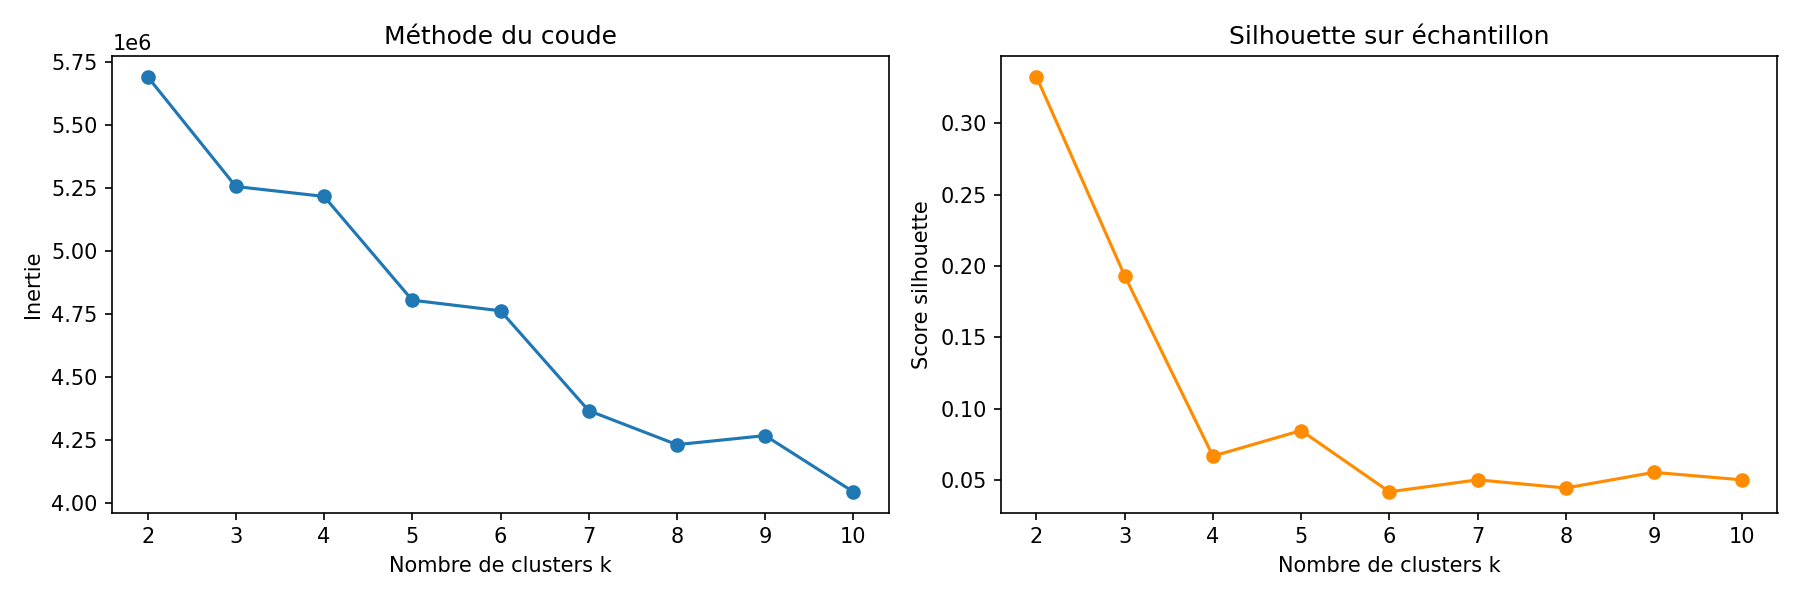

k retenu : 2 | silhouette échantillon : 0.3326


In [3]:
scores = pd.read_csv(OUT_DIR / "instacart_scores_k.csv")
display(scores.round(4))
display(Image(filename=str(OUT_DIR / "instacart_coude_silhouette.png")))

k_retenu = rapport["k_selected_by_highest_sample_silhouette"]
score_retenu = scores.loc[scores["k"].eq(k_retenu), "silhouette_echantillon"].iloc[0]
print(f"k retenu : {k_retenu} | silhouette échantillon : {score_retenu:.4f}")

## 3. Profils clients obtenus

Les statistiques ci-dessous sont des moyennes par segment. La « part du département » correspond à la proportion d’articles de ce département dans les paniers historiques.

In [4]:
profils = pd.read_csv(OUT_DIR / "instacart_profils_segments.csv").set_index("cluster")
colonnes_resume = [
    "n_clients", "part_clients", "prior_order_count", "mean_days_between_orders",
    "mean_basket_size", "reorder_rate", "mean_order_hour",
    "weekend_order_share", "evening_order_share", "departments_covered",
    "departement_dominant",
]
display(profils[colonnes_resume].round(3))

parts = [c for c in profils.columns if c.startswith("share_department_")]
top_departements = profils[parts].T
top_departements.index = top_departements.index.str.replace("share_department_", "", regex=False)
display(top_departements.loc[top_departements.max(axis=1).sort_values(ascending=False).head(8).index].round(3))

,n_clients,part_clients,prior_order_count,mean_days_between_orders,mean_basket_size,reorder_rate,mean_order_hour,weekend_order_share,evening_order_share,departments_covered,departement_dominant
cluster,,,,,,,,,,,
0,21457,0.104,11.939,16.774,7.575,0.344,13.899,0.310,0.267,10.111,household
1,184752,0.896,16.014,15.028,10.228,0.443,13.708,0.321,0.239,10.911,produce


cluster,0,1
produce,0.132,0.296
dairy_eggs,0.112,0.161
household,0.139,0.017
beverages,0.133,0.093
personal_care,0.094,0.008
snacks,0.086,0.089
frozen,0.064,0.072
pantry,0.064,0.060


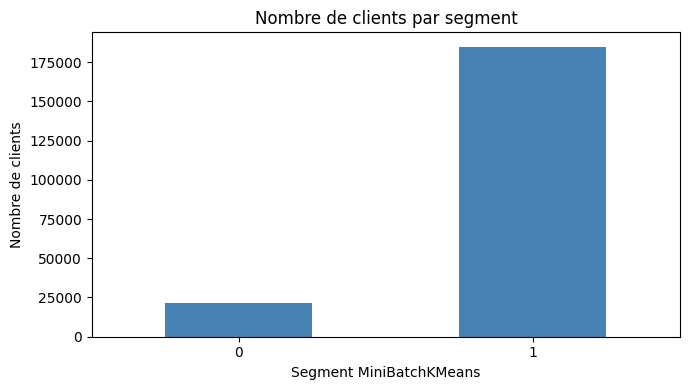

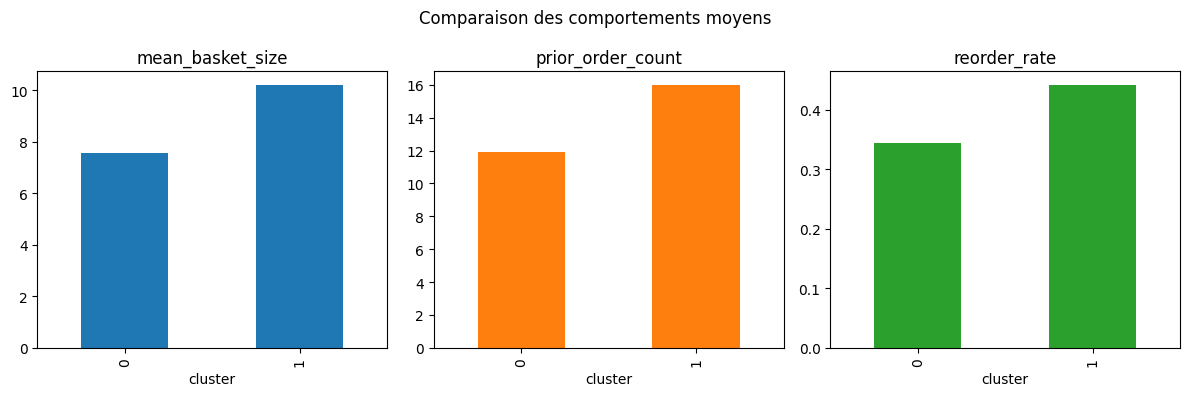

In [5]:
profils["n_clients"].plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.title("Nombre de clients par segment")
plt.xlabel("Segment MiniBatchKMeans")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

profils[["mean_basket_size", "prior_order_count", "reorder_rate"]].plot(
    kind="bar", subplots=True, layout=(1, 3), figsize=(12, 4), legend=False
)
plt.suptitle("Comparaison des comportements moyens")
plt.tight_layout()
plt.show()

## 4. Interprétation et limites

Le choix de k est un compromis statistique et métier : le meilleur score silhouette de l’échantillon est retenu ici, puis les profils permettent de vérifier si les segments sont compréhensibles. Un score modéré et un segment très majoritaire signalent que les frontières ne sont pas parfaites; il faudra tester la stabilité et discuter les profils avec l’équipe.

Les fichiers produits contiennent un `cluster` par `user_id` pseudonymisé et un résumé par segment. Cette analyse concerne l’échantillon public Instacart, pas les vrais clients de Panier Vert. Elle n’est pas le modèle supervisé de réachat et ne constitue pas encore une recommandation métier validée.